# Reservas con pagos observados: chain ladder y contraste retrospectivo

## Decisión y estimando
¿Cuánto pago adicional hasta edad 10 anticiparía un equipo actuarial al cierre de 2007 y qué error habría cometido frente a los pagos observados posteriormente? La estimación utiliza solo pagos acumulados visibles al cierre y compara contra una referencia simple de cero pagos futuros. No pretende validar reservas actuales.

**Resultado de este caso:** al cierre de 2007 se estimaron 13.122.496 unidades de pagos adicionales hasta edad 10 frente a 13.458.704 observadas después, con WAPE 2,50 % en nueve cohortes. Son valores históricos en la escala original de CAS, sin factor de cola ni validación de una reserva actual.

## Fuente y corte histórico
Datos de seguro de automóvil de pasajeros de EE. UU., fuente [CAS: NAIC Schedule P compilado para CAS por S&P Global Market Intelligence](https://www.casact.org/publications-research/research/research-resources/loss-reserving-data-pulled-naic-schedule-p). Es obligatorio reconocer CAS/S&P en publicaciones. Años de accidente 1998–2007; se selecciona previamente el grupo State Farm (código 1767), como caso ilustrativo y no representativo. Los montos conservan la escala original del archivo CAS; no se convierten a moneda local.

La fotografía de decisión es 31/12/2007. El desarrollo posterior se mantiene oculto al ajustar factores y se usa solo para comparar pagos acumulados hasta edad 10. Esto no reproduce la reserva contable reportada en 2007: no hay cola más allá de edad 10, gastos adicionales, descuento, reaseguro propio de otra cartera, ni pagos futuros desde hoy. La implementación requiere `pandas`, `numpy`, `matplotlib`, Jupyter y `curl`. La primera ejecución descarga el CSV de CAS; se comprueba SHA-256 y se detiene si cambia el archivo. Los datos externos no se redistribuyen en esta carpeta.

## Preparación y controles de calidad

In [1]:
from pathlib import Path
import importlib.util, pandas as pd, numpy as np, matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
project=root/'03-financial-risk/05-enterprise-risk-advisory/06-insurance-climate-esg/insurance-reserving'
spec=importlib.util.spec_from_file_location('cas_chainladder',project/'cas_chainladder.py')
cas=importlib.util.module_from_spec(spec);spec.loader.exec_module(cas)
data,sha=cas.load_data(project/'data/ppauto_pos98-07.csv')
print('Huella fuente:',sha, '| Grupo:',data.GRNAME.iloc[0], '| Filas:',len(data))

Huella fuente: 6e838f1e44c67218133ef1c8e28ca2b34b9f21ba4ee94de408c412638f798d96 | Grupo: State Farm Mut Grp | Filas: 100


In [2]:
assert data.AccidentYear.between(1998,2007).all()
assert set(data.DevelopmentLag)==set(range(1,11))
assert not data.duplicated(['AccidentYear','DevelopmentLag']).any()
triangle=data.pivot(index='AccidentYear',columns='DevelopmentLag',values='CumPaidLoss')
print('Celdas:',triangle.size,'| faltantes:',int(triangle.isna().sum().sum()))
print('Descensos en pagos acumulados entre edades:',int((triangle.diff(axis=1).iloc[:,1:]<0).sum().sum()))
observado=triangle.copy()
for year in observado.index:
    observado.loc[year,[j for j in observado.columns if year+j-1>2007]]=np.nan
print('Triángulo disponible al cierre de 2007:')
observado.round(0)

Celdas: 100 | faltantes: 0
Descensos en pagos acumulados entre edades: 0
Triángulo disponible al cierre de 2007:


DevelopmentLag,1,2,3,4,5,6,7,8,9,10
AccidentYear,,,,,,,,,,
1998,4303375,7133592.0,8477624.0,9255307.0,9654867.0,9834502.0,9924830.0,9972600.0,9995759.0,10012517.0
1999,4435838,7405295.0,8793040.0,9533668.0,9909823.0,10105800.0,10207638.0,10254349.0,10283286.0,NaN
2000,4795841,8101795.0,9465687.0,10207736.0,10632599.0,10829868.0,10928685.0,10981123.0,NaN,NaN
2001,5328657,8821829.0,10242503.0,11064259.0,11503526.0,11720590.0,11837901.0,NaN,NaN,NaN
2002,5859623,9417183.0,10927019.0,11776896.0,12245981.0,12490512.0,NaN,NaN,NaN,NaN
2003,5503855,8822501.0,10228154.0,11082963.0,11561287.0,NaN,NaN,NaN,NaN,NaN
2004,5234002,8449383.0,9834560.0,10710159.0,NaN,NaN,NaN,NaN,NaN,NaN
2005,5168064,8339198.0,9772146.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006,5173526,8386582.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Ajuste: factores observables en 2007
Para cada edad $j$, el factor ponderado por volumen es $f_j=\sum_i C_{i,j+1}/\sum_i C_{i,j}$ sobre pares cuyo segundo valor ya estaba disponible al cierre. La proyección a edad 10 multiplica el pago de la diagonal por los factores restantes; no se estima un factor de cola.

In [3]:
factors,results=cas.backtest(data,cutoff=2007)
factors.round(5)

,lag,n_pairs,factor
0,1,9,1.63478
1,2,8,1.16920
2,3,7,1.08331
3,4,6,1.04112
4,5,5,1.01918
5,6,4,1.00961
6,7,3,1.00473
7,8,2,1.00258
8,9,1,1.00168


## Control de filtración futura
Cambiar las celdas posteriores a 2007 no puede modificar los factores ajustados. La comprobación siguiente altera solo copias y compara factores; los valores observados no se modifican.

In [4]:
altered=data.copy(); altered.loc[altered.calendar_year>2007,'CumPaidLoss']*=9
assert np.allclose(cas.fit_factors(data,2007).factor,cas.fit_factors(altered,2007).factor)
print('Sin filtración de las celdas posteriores al cierre en el ajuste de factores.')

Sin filtración de las celdas posteriores al cierre en el ajuste de factores.


## Contraste con datos reservados
La referencia sin desarrollo proyecta pagos futuros cero. El error es estimado menos pago futuro observado hasta edad 10; se muestran error absoluto y WAPE agregado. No se infiere desempeño fuera de esta cartera y ventana.

In [5]:
results['error_baseline']=-results.future_paid_age10
metrics=pd.DataFrame({'método':['Chain ladder','Sin desarrollo'], 'error_abs_sum':[results.error.abs().sum(),results.error_baseline.abs().sum()]})
metrics['WAPE']=metrics.error_abs_sum/results.future_paid_age10.abs().sum()
display(results.round(2));display(metrics.round(4))
print('Pago futuro observado hasta edad 10:',round(results.future_paid_age10.sum(),2))

,AccidentYear,age,paid_to_cutoff,predicted_age10,actual_age10,reserve_predicted,future_paid_age10,error,error_baseline
0,2007,1,5365237.0,12008367.35,12061902,6643130.35,6696665.0,-53534.65,-6696665.0
1,2006,2,8386582.0,11482101.65,11554417,3095519.65,3167835.0,-72315.35,-3167835.0
2,2005,3,9772146.0,11442979.16,11511377,1670833.16,1739231.0,-68397.84,-1739231.0
3,2004,4,10710159.0,11576910.93,11630041,866751.93,919882.0,-53130.07,-919882.0
4,2003,5,11561287.0,12003350.87,12057898,442063.87,496611.0,-54547.13,-496611.0
5,2002,6,12490512.0,12724110.53,12738347,233598.53,247835.0,-14236.47,-247835.0
6,2001,7,11837901.0,11944519.38,11953731,106618.38,115830.0,-9211.62,-115830.0
7,2000,8,10981123.0,11027863.08,11033560,46740.08,52437.0,-5696.92,-52437.0
8,1999,9,10283286.0,10300526.04,10305664,17240.04,22378.0,-5137.96,-22378.0


,método,error_abs_sum,WAPE
0,Chain ladder,3.362080e+05,0.025
1,Sin desarrollo,1.345870e+07,1.000


Pago futuro observado hasta edad 10: 13458704.0


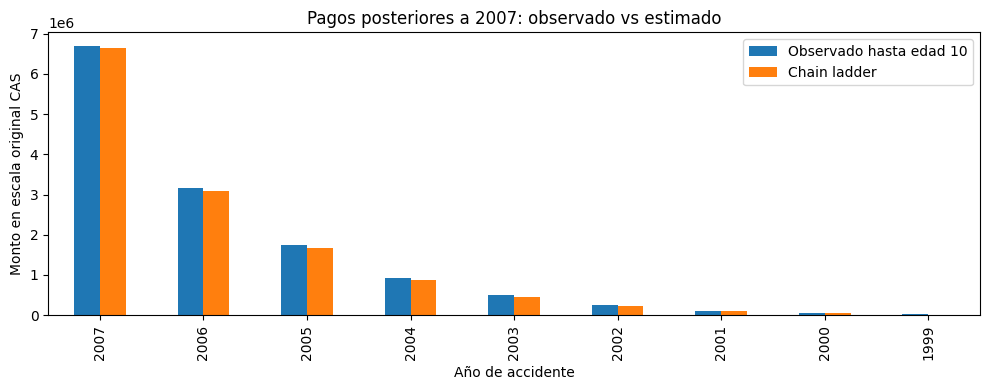

In [6]:
ax=results.set_index('AccidentYear')[['future_paid_age10','reserve_predicted']].plot.bar(figsize=(10,4),title='Pagos posteriores a 2007: observado vs estimado')
ax.set(xlabel='Año de accidente',ylabel='Monto en escala original CAS');ax.legend(['Observado hasta edad 10','Chain ladder']);plt.tight_layout();plt.show()

## Interpretación y decisión
Utilice el error por cohorte y los pares disponibles por edad para detectar una proyección frágil, no para certificar suficiencia de reservas actuales. La estabilidad de factores y representatividad del caso son supuestos; una validación actuarial real necesita triángulos vigentes, cambios de exposición y mix, tratamiento de siniestros grandes, cola, reservas incurridas y conciliación financiera. Un único caso retrospectivo no estima cobertura de intervalos ni acredita el cumplimiento IFRS 17.